# 05 — Calibration and cross-talk sensitivity

**Portfolio / learning project — not a calibrated instrument simulator.** All quantities below are synthetic proxies, literature-derived presets, or engineering estimates (see the [provenance table](../docs/model_details.md#data-provenance)).

This notebook is narrative and self-contained; run the cells top to bottom.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / 'src'))
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
FIG = pathlib.Path.cwd().parent / 'figures' / 'notebooks'
FIG.mkdir(parents=True, exist_ok=True)


## How calibration errors bias the science
We probe three sensitivities: a **wavelength-calibration offset** (-> velocity bias `dv = c d_lambda/lambda`), increasing **cross-talk** (-> leakage between spaxels), and increasing **read noise** (-> SNR loss). All are internal trend checks, not instrument predictions.

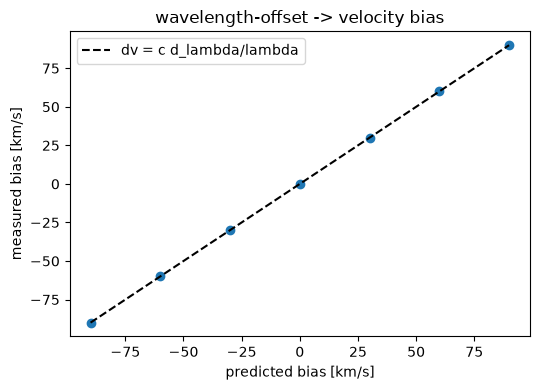

In [2]:
from ao_fed_ifu.source_cube import SourceCubeConfig, create_emission_line_cube, create_point_source_cube, scale_cube_to_total_electrons
from ao_fed_ifu.spectrograph_model import SpectrographConfig
from ao_fed_ifu.ifu_mapping import IFUConfig, build_slicer_mapping, forward_project_cube
from ao_fed_ifu import cube_reconstruction as recon, diagnostics as diag
from ao_fed_ifu import SPEED_OF_LIGHT_KM_S

spectro = SpectrographConfig(lambda_min_um=2.1, lambda_max_um=2.3, resolving_power_R=4000.0)
cfg = SourceCubeConfig(nx=8, ny=8, nlambda=spectro.n_detector_pixels, lambda_min_um=2.1, lambda_max_um=2.3)
wl = cfg.wavelength_grid_um; centre = spectro.lambda_mid_um
cube = create_emission_line_cube(cfg, line_center_um=centre, line_flux_rel=12.0, line_sigma_um=0.0004)
cube = scale_cube_to_total_electrons(cube, 2e6)
mapping = build_slicer_mapping(IFUConfig(nx_spaxel=cfg.nx, ny_spaxel=cfg.ny), spectro, wl)
rebuilt = recon.reconstruct_cube_nearest(forward_project_cube(cube, mapping, apply_cross_talk=False), mapping)

offsets = np.linspace(-3, 3, 7) * cfg.delta_lambda_um
meas, pred = [], []
v0 = np.nanmedian(diag.velocity_centroid_map(rebuilt, wl, centre, 0.0025))
for d in offsets:
    v = np.nanmedian(diag.velocity_centroid_map(rebuilt, wl + d, centre, 0.0025))
    meas.append(v - v0); pred.append(SPEED_OF_LIGHT_KM_S * d / centre)
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.plot(np.array(pred), np.array(meas), 'o'); lim=[min(pred), max(pred)]
ax.plot(lim, lim, 'k--', label='dv = c d_lambda/lambda'); ax.legend()
ax.set_xlabel('predicted bias [km/s]'); ax.set_ylabel('measured bias [km/s]')
ax.set_title('wavelength-offset -> velocity bias'); fig.tight_layout()
fig.savefig(FIG / 'nb05_velocity_bias.png', dpi=110); plt.show()

## Cross-talk leakage vs sigma

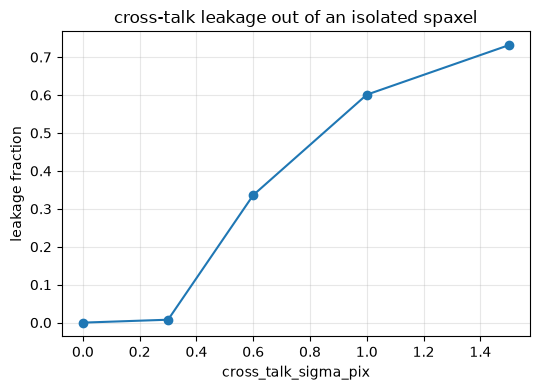

In [3]:
ptcube = create_point_source_cube(cfg, line_flux_rel=5.0)
ptcube = scale_cube_to_total_electrons(ptcube, 1e5)
cx, cy = cfg.nx//2, cfg.ny//2
sigmas = [0.0, 0.3, 0.6, 1.0, 1.5]
leak = []
for s in sigmas:
    ifu = IFUConfig(nx_spaxel=cfg.nx, ny_spaxel=cfg.ny, cross_talk_sigma_pix=s)
    mp = build_slicer_mapping(ifu, spectro, wl)
    fr = forward_project_cube(ptcube, mp, apply_lsf=False, apply_cross_talk=True)
    rb = recon.reconstruct_cube_nearest(fr, mp)
    leak.append(diag.cross_talk_fraction(rb, cx, cy))
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.plot(sigmas, leak, 'o-'); ax.set_xlabel('cross_talk_sigma_pix'); ax.set_ylabel('leakage fraction')
ax.set_title('cross-talk leakage out of an isolated spaxel'); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(FIG / 'nb05_crosstalk.png', dpi=110); plt.show()
pd.DataFrame({'cross_talk_sigma_pix': sigmas, 'leakage_fraction': leak}).to_csv(FIG / 'nb05_summary.csv', index=False)